<a href="https://colab.research.google.com/github/Priya-DharshiniRamesh/24ADI006_DEEP-LEARNING/blob/main/DL_EXP_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**DEEP LEARNING -24ADI006**

**EXPT NO: 8	GENERATION OF SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)**

**Name: Priya Dharshini R**\
**Roll no: 24BAD092**

**AIM**

To implement and train a Generative Adversarial Network (GAN) to generate synthetic images by training a Generator and a Discriminator in an adversarial learning framework.



**SOFTWARE REQUIREMENTS**

•	Python

•	TensorFlow / Keras / PyTorch

•	Google Colab

•	GitHub

•	NumPy

•	Matplotlib

•	Pandas

•	Scikit-learn


**OBJECTIVES**

**Students will be able to:**

•	Understand the architecture and working of Generative Adversarial Networks.

•	Identify the functions of the Generator and Discriminator.

•	Prepare image datasets for GAN training.

•	Generate random noise vectors as inputs to the Generator.

•	Build and train a simple GAN using a suitable dataset.

•	Understand adversarial training and the associated loss functions.

•	Generate synthetic images and visualize the results.

•	Evaluate the quality and diversity of generated images through visual inspection.

•	Document the experiment and manage the notebook using GitHub.


**PART A: DATASET PREPARATION**

**Perform the following tasks:**

•	Load an image dataset, such as MNIST, and display sample images.

•	Explore the image dimensions and pixel-value range.

•	Normalize and reshape the images according to the GAN input requirements.

•	Prepare batches of real images for training.


Student Name: Priya Dharshini R
Roll No: 24BAD092
TensorFlow Version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Data type: uint8
Original pixel range: (np.uint8(0), np.uint8(255))


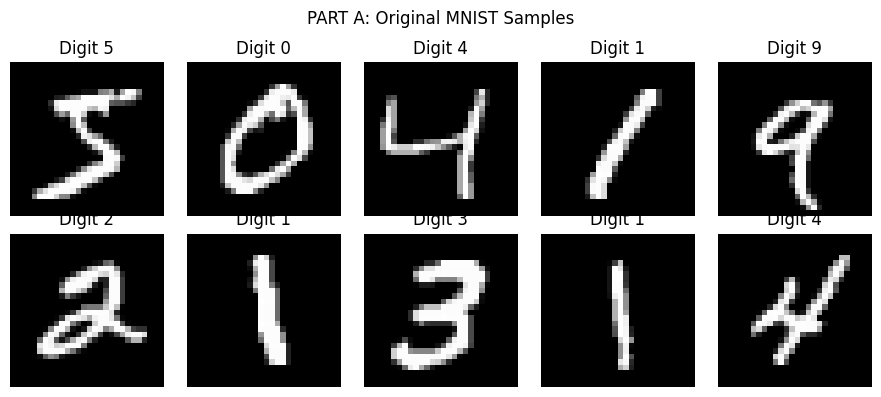

Normalized image shape: (60000, 28, 28, 1)
Normalized pixel range: (np.float32(-1.0), np.float32(1.0))
Number of training batches: 234
Priya Dharshini R (24BAD092)


In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

# Set random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Original pixel range:", (x_train.min(), x_train.max()))

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(9, 4))

for ax, img, label in zip(axes.ravel(), x_train[:10], y_train[:10]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Digit {label}")
    ax.axis("off")

plt.suptitle("PART A: Original MNIST Samples")
plt.tight_layout()
plt.show()

# Normalize images to range [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Reshape images
x_train = x_train[..., np.newaxis]

# Prepare batches
BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_ds = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Normalized image shape:", x_train.shape)
print("Normalized pixel range:", (x_train.min(), x_train.max()))
print("Number of training batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Priya Dharshini R (24BAD092)")

**PART B: IMPLEMENTING THE GENERATOR AND DISCRIMINATOR**

**Perform the following tasks:**

•	Build a Generator model to create synthetic images from random noise vectors.

•	Build a Discriminator model to classify images as real or generated.

•	Select suitable layers, activation functions, optimizer, and loss function.

•	Combine the Generator and Discriminator to construct the GAN.

•	Display the model summaries.


In [2]:
# Dimension of random noise
NOISE_DIM = 100

# Build Generator
def build_generator():

    noise = layers.Input(shape=(NOISE_DIM,), name="noise_vector")

    x = layers.Dense(7 * 7 * 128, use_bias=False)(noise)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Reshape((7, 7, 128))(x)

    x = layers.Conv2DTranspose(
        64, 5, strides=2, padding="same", use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    image = layers.Conv2DTranspose(
        1, 5, strides=2, padding="same", activation="tanh"
    )(x)

    return Model(noise, image, name="Generator")


# Build Discriminator
def build_discriminator():

    image = layers.Input(shape=(28, 28, 1), name="input_image")

    x = layers.Conv2D(64, 5, strides=2, padding="same")(image)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, 5, strides=2, padding="same")(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)

    logit = layers.Dense(1)(x)

    return Model(image, logit, name="Discriminator")


# Create models
generator = build_generator()
discriminator = build_discriminator()

# Combine Generator and Discriminator
gan = Model(
    generator.input,
    discriminator(generator.output),
    name="Combined_GAN"
)

# Loss function and optimizers
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4, beta_1=0.5
)

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4, beta_1=0.5
)

# Display model summaries
print("\nGENERATOR SUMMARY")
generator.summary()

print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()

print("\nCOMBINED GAN SUMMARY")
gan.summary()

# Check generated image shape
sample_noise = tf.random.normal([1, NOISE_DIM])
sample_image = generator(sample_noise, training=False)

print("Generated image shape:", sample_image.shape)

print("Priya Dharshini R (24BAD092)")


GENERATOR SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise_vector (InputLayer)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,945 (3.28 MB)

 Trainable params: 846,273 (3.23 MB)

 Non-trainable params: 12,672 (49.50 KB)

... (9 outputs left out)

 Total params: 1,071,810 (4.09 MB)

 Trainable params: 1,059,138 (4.04 MB)

 Non-trainable params: 12,672 (49.50 KB)

Generated image shape: (1, 28, 28, 1)
Priya Dharshini R (24BAD092)


**PART C: GAN TRAINING AND PERFORMANCE MONITORING**

**Perform the following tasks:**

•	Train the Discriminator using real and generated images.

•	Train the Generator to produce realistic images.

•	Alternate the training of both models for a suitable number of epochs.

•	Record and plot Generator and Discriminator losses.

•	Display sample generated images during training.


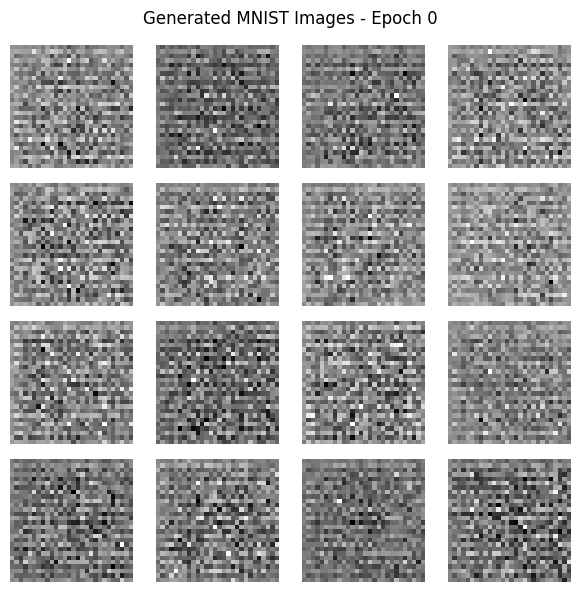

Epoch 01/10 | Generator Loss: 0.7912 | Discriminator Loss: 1.0376


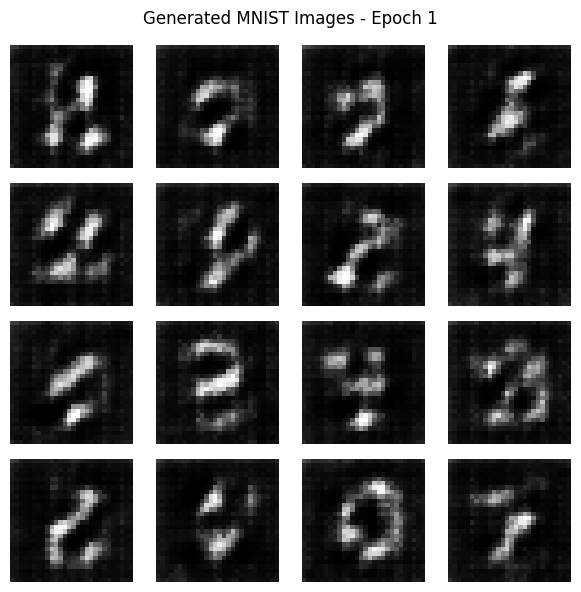

Epoch 02/10 | Generator Loss: 0.8232 | Discriminator Loss: 1.2377
Epoch 03/10 | Generator Loss: 0.8131 | Discriminator Loss: 1.2605
Epoch 04/10 | Generator Loss: 0.8380 | Discriminator Loss: 1.2395
Epoch 05/10 | Generator Loss: 0.8712 | Discriminator Loss: 1.2108


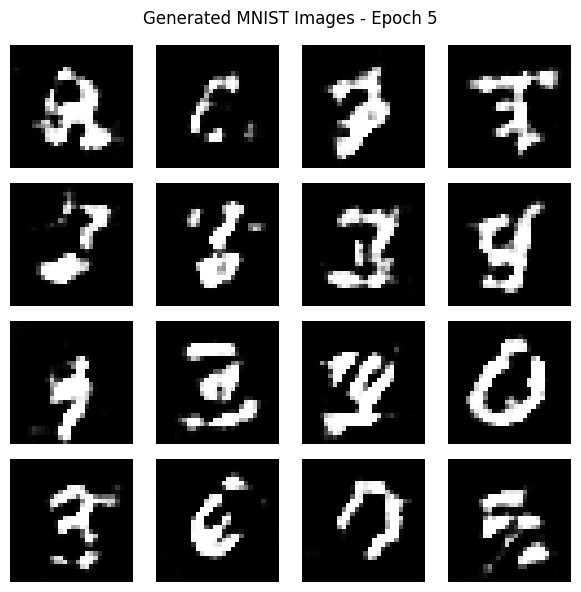

Epoch 06/10 | Generator Loss: 0.9200 | Discriminator Loss: 1.1641
Epoch 07/10 | Generator Loss: 0.9647 | Discriminator Loss: 1.1266
Epoch 08/10 | Generator Loss: 0.9940 | Discriminator Loss: 1.1152
Epoch 09/10 | Generator Loss: 0.9798 | Discriminator Loss: 1.1477
Epoch 10/10 | Generator Loss: 0.9425 | Discriminator Loss: 1.1864


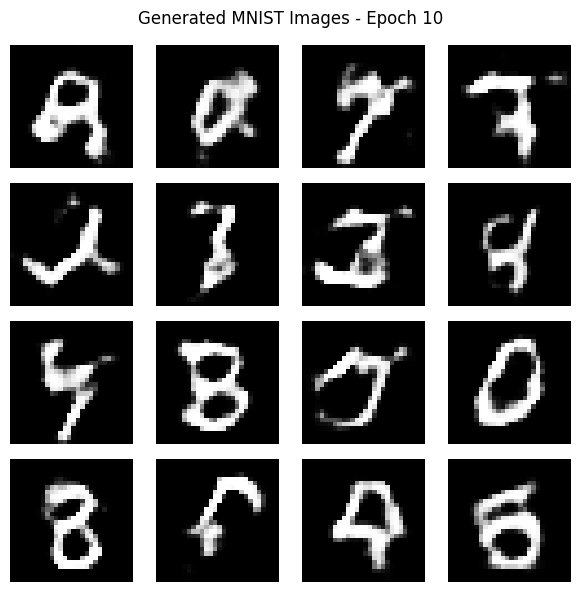


LOSS HISTORY
 epoch  generator_loss  discriminator_loss
     1        0.791181            1.037555
     2        0.823166            1.237658
     3        0.813055            1.260451
     4        0.838026            1.239491
     5        0.871167            1.210776
     6        0.920005            1.164124
     7        0.964739            1.126570
     8        0.993980            1.115161
     9        0.979807            1.147675
    10        0.942461            1.186440


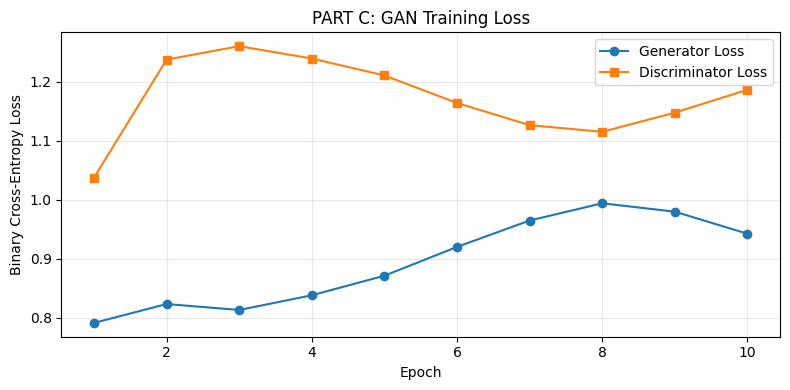

Priya Dharshini R (24BAD092)


In [3]:
# Number of training epochs
EPOCHS = 10

# Fixed noise for displaying generated images
FIXED_NOISE = tf.random.normal([16, NOISE_DIM], seed=SEED)


# Discriminator loss
def discriminator_loss(real_logits, fake_logits):

    real_loss = loss_fn(
        tf.ones_like(real_logits), real_logits
    )

    fake_loss = loss_fn(
        tf.zeros_like(fake_logits), fake_logits
    )

    return real_loss + fake_loss


# Generator loss
def generator_loss(fake_logits):

    return loss_fn(
        tf.ones_like(fake_logits), fake_logits
    )


# Training step
@tf.function
def train_step(real_images):

    noise = tf.random.normal(
        [tf.shape(real_images)[0], NOISE_DIM]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)

        g_loss = generator_loss(fake_logits)
        d_loss = discriminator_loss(real_logits, fake_logits)

    # Calculate gradients
    g_grads = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_grads = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    # Update model weights
    g_optimizer.apply_gradients(
        zip(g_grads, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(d_grads, discriminator.trainable_variables)
    )

    return g_loss, d_loss


# Display generated images
def show_generated_images(epoch, noise=FIXED_NOISE):

    predictions = generator(noise, training=False).numpy()

    predictions = np.clip(
        (predictions + 1.0) / 2.0, 0.0, 1.0
    )

    fig, axes = plt.subplots(4, 4, figsize=(6, 6))

    for ax, image in zip(axes.flat, predictions):
        ax.imshow(image.squeeze(), cmap="gray")
        ax.axis("off")

    plt.suptitle(f"Generated MNIST Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()


# Store training losses
history = {
    "epoch": [],
    "generator_loss": [],
    "discriminator_loss": []
}

# Display initial generated images
show_generated_images(0)

# Train GAN
for epoch in range(1, EPOCHS + 1):

    g_avg = tf.keras.metrics.Mean()
    d_avg = tf.keras.metrics.Mean()

    for real_batch in train_ds:

        g_loss, d_loss = train_step(real_batch)

        g_avg.update_state(g_loss)
        d_avg.update_state(d_loss)

    history["epoch"].append(epoch)
    history["generator_loss"].append(float(g_avg.result()))
    history["discriminator_loss"].append(float(d_avg.result()))

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Generator Loss: {g_avg.result():.4f} | "
        f"Discriminator Loss: {d_avg.result():.4f}"
    )

    if epoch in {1, 5, EPOCHS}:
        show_generated_images(epoch)


# Create loss history table
loss_df = pd.DataFrame(history)

print("\nLOSS HISTORY")
print(loss_df.to_string(index=False))


# Plot Generator and Discriminator losses
plt.figure(figsize=(8, 4))

plt.plot(
    loss_df["epoch"],
    loss_df["generator_loss"],
    marker="o",
    label="Generator Loss"
)

plt.plot(
    loss_df["epoch"],
    loss_df["discriminator_loss"],
    marker="s",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("PART C: GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Priya Dharshini R (24BAD092)")

**PART D: SYNTHETIC IMAGE GENERATION, VISUALIZATION AND EXPERIMENT MANAGEMENT**

**Perform the following tasks:**

•	Generate synthetic images using the trained Generator.

•	Display and compare generated images with original dataset samples.

•	Observe the quality, diversity, and recognizability of generated images.

•	Document the experiment and upload the notebook to GitHub


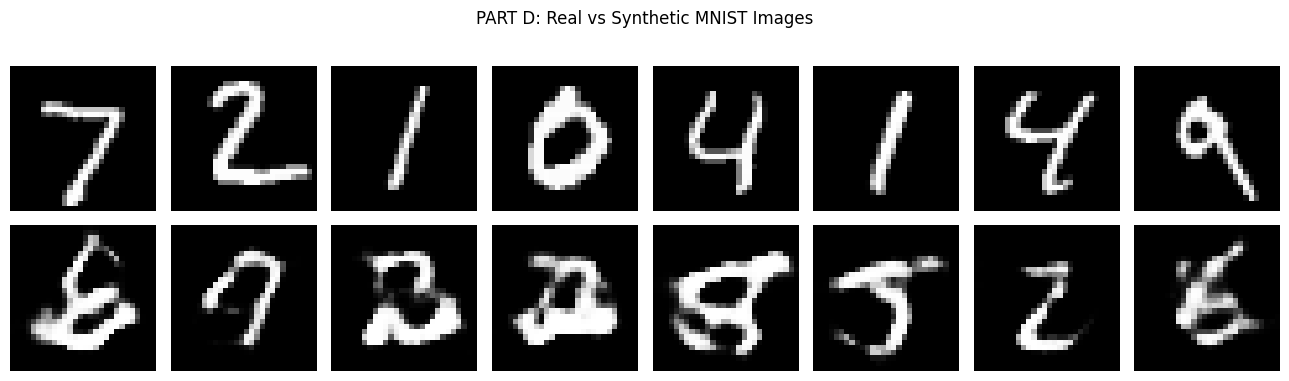

Noise vector dimension: 100
Synthetic image dimensions: (16, 28, 28, 1)
Mean across-image pixel standard deviation: 0.1636
Observe the generated images for quality, diversity and recognizability.
Generator model saved successfully.
Training loss table saved successfully.
Priya Dharshini R (24BAD092)


In [4]:
# Generate new random noise
new_noise = tf.random.normal(
    [16, NOISE_DIM], seed=2026
)

# Generate synthetic images
synthetic = generator(
    new_noise, training=False
).numpy()

# Convert images to range [0, 1]
synthetic = np.clip(
    (synthetic + 1) / 2, 0, 1
)


# Compare real and generated images
fig, axes = plt.subplots(2, 8, figsize=(13, 4))

for i in range(8):

    # Original real images
    axes[0, i].imshow(
        x_test[i], cmap="gray", vmin=0, vmax=255
    )

    # Generated synthetic images
    axes[1, i].imshow(
        synthetic[i].squeeze(), cmap="gray", vmin=0, vmax=1
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Real", fontsize=12)
axes[1, 0].set_ylabel("Generated", fontsize=12)

plt.suptitle("PART D: Real vs Synthetic MNIST Images")
plt.tight_layout()
plt.show()


# Display image information
flattened = synthetic.reshape(16, -1)

mean_pixel_std = float(
    np.std(flattened, axis=0).mean()
)

print("Noise vector dimension:", NOISE_DIM)
print("Synthetic image dimensions:", synthetic.shape)

print(
    "Mean across-image pixel standard deviation:",
    round(mean_pixel_std, 4)
)

print(
    "Observe the generated images for quality, "
    "diversity and recognizability."
)


# Save trained Generator
generator.save("gan_generator.keras")

# Save training losses
loss_df.to_csv("gan_training_losses.csv", index=False)

print("Generator model saved successfully.")
print("Training loss table saved successfully.")

print("Priya Dharshini R (24BAD092)")

**OBSERVATION:**
1. The Generator produced synthetic MNIST images using random noise.

2. Some generated digits are recognizable, while others are distorted.

3. The generated images show variations in shape and appearance.

4. Image quality can improve with further training.

**Result**

In [5]:
print("RESULT")

print(
    "A Generative Adversarial Network (GAN) was "
    "successfully implemented using the MNIST dataset."
)

print(
    "The Generator and Discriminator were trained "
    "using adversarial learning."
)

print(
    "Synthetic images were generated and compared "
    "with original MNIST images."
)

print(
    "Generator and Discriminator loss curves were "
    "plotted to monitor training performance."
)

print("Name: Priya Dharshini R")
print("Roll No: 24BAD092")

RESULT
A Generative Adversarial Network (GAN) was successfully implemented using the MNIST dataset.
The Generator and Discriminator were trained using adversarial learning.
Synthetic images were generated and compared with original MNIST images.
Generator and Discriminator loss curves were plotted to monitor training performance.
Name: Priya Dharshini R
Roll No: 24BAD092
